# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las celdas marcadas con `# TODO` son las que debes completar.


---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.13.2
Backend       : tensorflow


---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [3]:
# El servidor original (cs.toronto.edu) estaba muy lento:
# se carga el mismo CIFAR-10 desde Hugging Face.
from datasets import load_dataset

ds = load_dataset("uoft-cs/cifar10")

X_train = np.stack([np.array(img) for img in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"])
X_test  = np.stack([np.array(img) for img in ds["test"]["img"]])
y_test  = np.array(ds["test"]["label"])

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [4]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Después de convertir las imágenes a escala de grises, cada imagen tiene tamaño `32×32`.

¿Cuántos valores tendrá cada imagen después de aplicar `Flatten()`?

**Respuesta:** 32 × 32 = 1024 valores. Flatten pone las 32 filas de 32 píxeles una
detrás de otra en un solo vector. Como la imagen está en escala de grises, hay un solo
valor por píxel; en RGB serían 32 × 32 × 3 = 3072.



## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [5]:
# TODO 1 — Normalización
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print(X_train.min(), X_train.max())


0.0 1.0


In [6]:
# Validación TODO 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


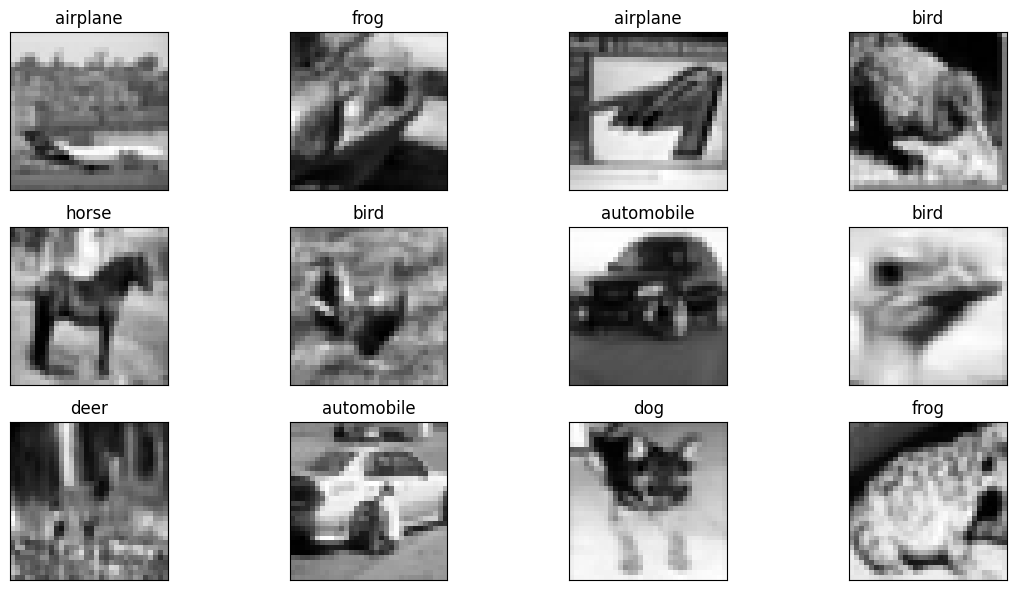

In [7]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [8]:
# TODO 2 — Completa la arquitectura
model = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,490 (517.54 KB)

 Trainable params: 132,490 (517.54 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Validación TODO 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Porque una capa Dense recibe un vector, no una matriz. La imagen llega como 32×32 y Flatten() la convierte en un vector de 1024 valores para que cada neurona de la capa Dense pueda conectarse con todos los píxeles.


**3.** ¿Por qué la última capa tiene 10 neuronas?

**Respuesta:** Porque CIFAR-10 tiene 10 clases. Cada neurona produce el puntaje (logit) de una clase, y la predicción es la clase con el puntaje más alto.


**4.** ¿Qué función cumple `ReLU`?

**Respuesta:** Introduce no linealidad: deja pasar los valores positivos y convierte los negativos en 0. Sin ella, apilar capas Dense equivaldría a una sola transformación lineal y la red no podría aprender patrones complejos.



---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [10]:
lr_rate = 0.001

# TODO 3 — Configura el entrenamiento
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)


### Pregunta 5

¿Por qué usamos `from_logits=True`?

**Respuesta:** Porque la última capa no tiene Softmax y entrega logits (puntajes sin normalizar). Con from_logits=True la función de pérdida aplica el Softmax internamente, lo que además es más estable numéricamente que hacerlo en la red.



---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [11]:
epochs = 10
batch_size = 64

# TODO 4 — Entrenamiento
history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.2525 - loss: 2.0671 - val_accuracy: 0.2880 - val_loss: 1.9996
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3153 - loss: 1.9255 - val_accuracy: 0.3174 - val_loss: 1.9155
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3391 - loss: 1.8647 - val_accuracy: 0.3310 - val_loss: 1.8777
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3524 - loss: 1.8282 - val_accuracy: 0.3465 - val_loss: 1.8364
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3622 - loss: 1.8005 - val_accuracy: 0.3508 - val_loss: 1.8214
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3702 - loss: 1.7776 - val_accuracy: 0.3543 - val_loss: 1.8129
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3773 - loss: 1.7609 - val_accuracy: 0.3644 - val_loss: 1.7906
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3828 - loss: 1.7456 - val_accuracy: 0.

### Preguntas

**6.** ¿Qué representa una `epoch`?

**Respuesta:** Una pasada completa del modelo por todo el conjunto de entrenamiento (las 50,000 imágenes). Con epochs=10, el modelo ve cada imagen 10 veces.


**7.** ¿Qué representa `batch_size=64`?

**Respuesta:** El número de imágenes que el modelo procesa antes de actualizar sus pesos.
Cada epoch tiene entonces 50,000 / 64 ≈ 782 actualizaciones.



## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


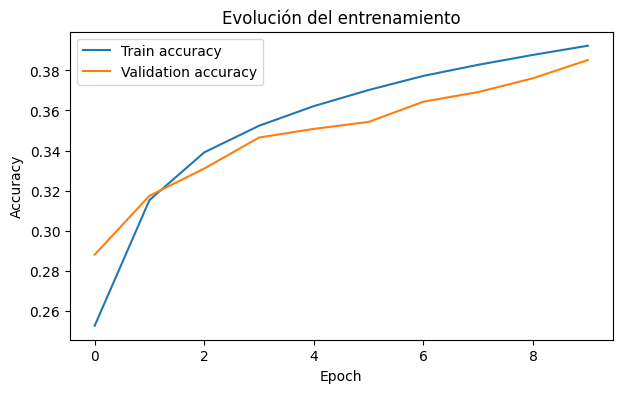

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ¿Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** No. Las curvas de entrenamiento y validación suben juntas durante las
10 epochs y terminan muy cerca (≈39 % vs ≈38.5 %). Habría overfitting si la de
entrenamiento siguiera subiendo mientras la de validación se estanca o baja, y eso no
ocurre.



---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [13]:
# TODO 5 — Evaluación
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 1.7429
Test accuracy : 0.3852
Accuracy (%)  : 38.52%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

¿CIFAR-10 en escala de grises parece más fácil o más difícil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** Mucho más difícil. Obtuvimos **38.52%** de accuracy, frente a cerca de 85–88 % en Fashion-MNIST con la misma arquitectura. En Fashion-MNIST las prendas están centradas, sobre fondo negro y con siluetas muy distintas. En CIFAR-10 los objetos aparecen en distintas posiciones, tamaños y fondos, y al quitar el color se pierde información útil (por ejemplo, el azul del cielo o del mar para aviones y barcos).



---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


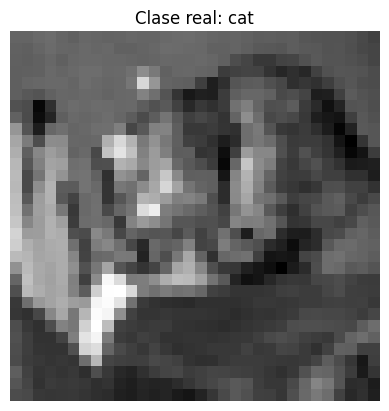

Logits:
[[ 0.93634135 -1.4649396   1.3190653   0.41935432  1.0572224   0.46724832
   1.7865167   0.5324518   0.08018976 -1.7842549 ]]


In [14]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [15]:
# TODO 6 — Logits -> probabilidades
probabilities = keras.ops.softmax(logits)

# TODO 7 — Clase con mayor probabilidad
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])

print("Clase real     :", class_names[true_class])
print("Clase predicha :", class_names[prediction])


Clase real     : cat
Clase predicha : frog


In [16]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.1190
automobile  : 0.0108
bird        : 0.1744
cat         : 0.0709
deer        : 0.1343
dog         : 0.0744
frog        : 0.2784 ← predicción
horse       : 0.0794
ship        : 0.0505
truck       : 0.0078

Suma: 1.0


### Pregunta 10

¿Por qué las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Porque Softmax convierte los logits en una distribución de probabilidad: aplica la exponencial a cada logit y divide por la suma de todas. Así cada valor queda entre 0 y 1 y juntos suman 1, porque la imagen pertenece a exactamente una de las 10 clases.



---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


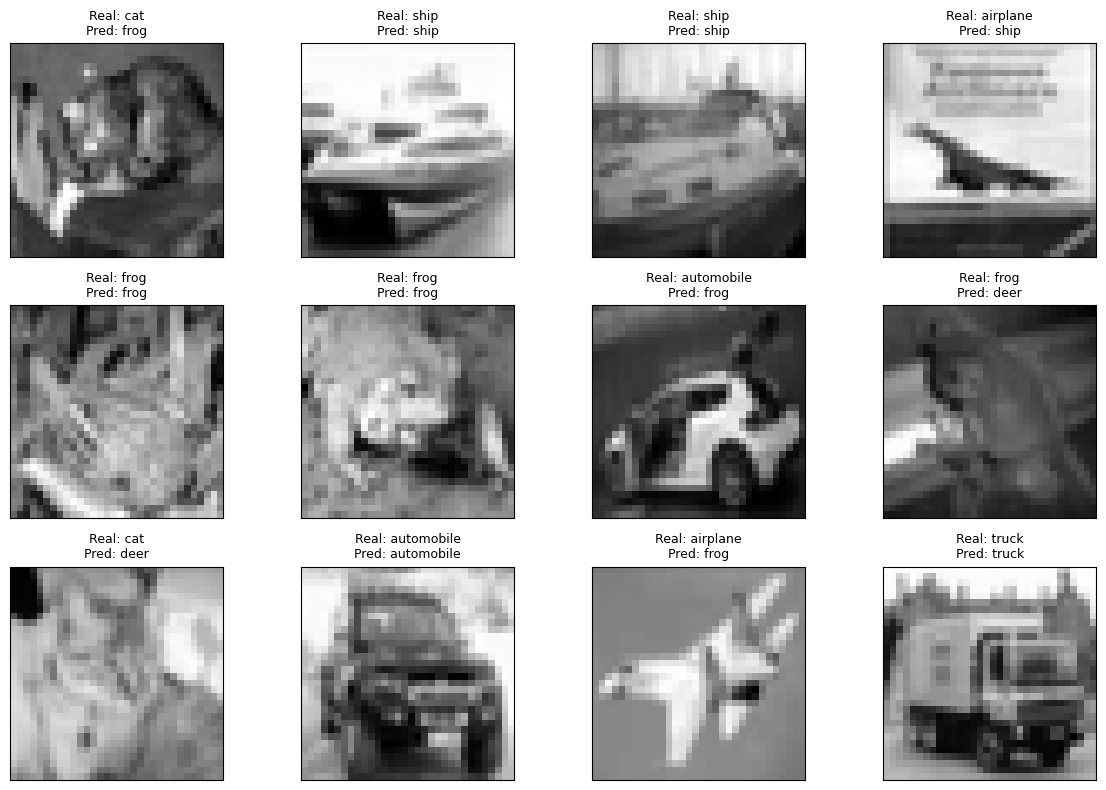

In [17]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 8. Reflexión final

### 1. ¿Cuál fue el accuracy final?

**Respuesta:** 38.52 % en el conjunto de test. Es bajo, pero bastante mejor que el 10 % que se obtendría adivinando al azar entre 10 clases


### 2. ¿Qué clases parecen más difíciles de distinguir?

**Respuesta:** Los animales entre sí (cat, frog, deer): en las 12 predicciones
confundió dos gatos con frog y deer, y una rana con deer. Además predijo "frog" para imágenes muy distintas (un gato, un automóvil y un avión), lo que sugiere que asocia esa clase con texturas irregulares más que con una forma. También confundió airplane con ship: ambos suelen aparecer sobre fondos uniformes (cielo o agua), y sin color esos fondos se parecen todavía más.


### 3. Después de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ¿Qué información importante sobre la imagen podría perderse al tratarla únicamente como un vector?

**Respuesta:** La estructura espacial: qué píxeles están cerca de cuáles. Al
aplanar, un píxel y su vecino de abajo quedan a 32 posiciones de distancia en el
vector, y la red no sabe que estaban juntos. Así se pierden bordes, formas y
patrones locales.


### 4. ¿Qué tipo de arquitectura podría aprovechar mejor la estructura espacial de las imágenes?

**Respuesta:** Las redes neuronales convolucionales (CNNs). Usan filtros pequeños que recorren la imagen detectando patrones locales (bordes, texturas, formas) en cualquier posición, conservando la relación entre píxeles vecinos.

---

## Para pensar

Nuestro modelo hace:

```text
32×32 → Flatten → 1024 valores → Dense → ReLU → Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **¿Cómo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta será: **Convolutional Neural Networks (CNNs)**.
